# Лабораторна робота № 4
**з дисципліни «Інтелектуальний аналіз даних»**

* **Тема:** Побудова та оцінювання моделі бінарної класифікації з коректним поділом даних, підготовкою різнотипних ознак у Pipeline та аналізом помилок.
* **Студентка:** Іващенко Каріна Дмитрівна
* **Група:** МІТ-31
* **Варіант індивідуального завдання:** 9 (Оцінка стабільності метрик у StratifiedKFold з 5 фолдами)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Фіксація генератора випадкових чисел для відтворюваності
SEED = 42
np.random.seed(SEED)

# Завантаження набору даних Titanic
df = sns.load_dataset("titanic")

# Вивід розмірності таблиці (рядки, стовпці)
print("Розмірність таблиці:", df.shape)

Розмірність таблиці: (891, 15)


Висновок до Етапу 1: Імпортовано необхідні бібліотеки, зафіксовано значення SEED = 42 для забезпечення відтворюваності експерименту. Завантажено набір даних Titanic, розмірність таблиці становить 891 рядок та 15 стовпці

--- HEAD ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

--- DESCRIBE ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Кількість дублікатів: 107 ---

--- Пропущені значення ---


,count,percent
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000



--- Баланс цільової змінної (частка) ---


,proportion
survived,
0,0.616162
1,0.383838


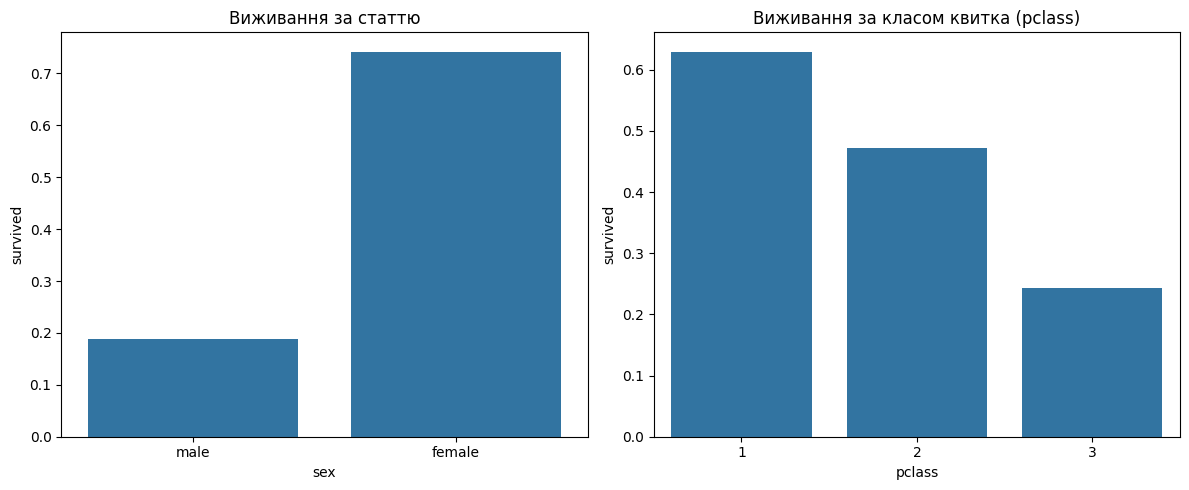

In [3]:
# 1. Первинний огляд даних
print("--- HEAD ---")
display(df.head())

print("\n--- INFO ---")
df.info()

print("\n--- DESCRIBE ---")
display(df.describe(include="all"))

print("\n--- Кількість дублікатів:", df.duplicated().sum(), "---")

# 2. Таблиця пропусків
missing = pd.DataFrame(
    {"count": df.isna().sum(), "percent": df.isna().mean().mul(100)}
).sort_values("percent", ascending=False)
print("\n--- Пропущені значення ---")
display(missing)

# 3. Баланс цільової змінної survived
class_balance = df["survived"].value_counts(normalize=True).sort_index()
print("\n--- Баланс цільової змінної (частка) ---")
display(class_balance)

# 4. Графіки (частка виживання за статтю та класом квитка)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=df, x="sex", y="survived", errorbar=None)
plt.title("Виживання за статтю")

plt.subplot(1, 2, 2)
# Використовуємо pclass, як вимагається в лабораторній
sns.barplot(data=df, x="pclass", y="survived", errorbar=None)
plt.title("Виживання за класом квитка (pclass)")

plt.tight_layout()
plt.show()

Висновок до Етапу 2: Проведено первинний аналіз даних. Виявлено пропущені значення у стовпцях age, deck, embark_town та інших (найбільше пропусків у стовпці deck). Пропуски в стовпці age вирішено не видаляти, а обробити пізніше всередині Pipeline. Досліджено баланс цільової змінної survived: значна частина пасажирів не вижила (клас 0 переважає). Візуалізація показала, що показники виживання помітно відрізняються залежно від статі та класу квитка.

In [4]:
# Копіюємо датасет, щоб не змінювати оригінальний df
data = df.copy()

# Створюємо новий ознаку FamilySize (додаємо 1, враховуючи самого пасажира)
data["family_size"] = data["sibsp"] + data["parch"] + 1

# Визначаємо списки числових та категоріальних ознак
numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
categorical_features = ["pclass", "sex", "embarked"]

# Формуємо матрицю ознак X та цільову змінну y (survived не входить до X)
X = data[numeric_features + categorical_features]
y = data["survived"]

print("Розмірність X:", X.shape)
print("Розмірність y:", y.shape)

Розмірність X: (891, 8)
Розмірність y: (891,)


Висновок до Етапу 3: Створено новий комбінований показник family_size (кількість членів родини разом із самим пасажиром). Виділено списки числових та категоріальних ознак відповідно до вимог. Змінна survived відокремлена як цільова змінна y і виключена з набору ознак X. Зайві та дублюючі стовпці відсіяно.

In [5]:
from sklearn.model_selection import train_test_split

# Поділ даних 80% / 20% зі стратифікацією за цільовою змінною
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Перевірка частки позитивного класу
print("Загальна частка (y):", round(y.mean(), 3))
print("Частка у тренувальній (y_train):", round(y_train.mean(), 3))
print("Частка у тестовій (y_test):", round(y_test.mean(), 3))
print("\nРозмір X_train:", X_train.shape, "| Розмір X_test:", X_test.shape)

Загальна частка (y): 0.384
Частка у тренувальній (y_train): 0.383
Частка у тестовій (y_test): 0.385

Розмір X_train: (712, 8) | Розмір X_test: (179, 8)


Висновок до Етапу 4: Виконано поділ набору даних у пропорції 80% для навчання та 20% для тестування з використанням stratify=y та random_state=SEED. Завдяки стратифікації частка позитивного класу (людей, що вижили) залишилася практично ідентичною в усіх вибірках (~38.4%), що забезпечить коректність подальшого навчання та оцінювання. Тестова вибірка ізольована і не використовуватиметься на етапах навчання.

In [6]:
from sklearn.dummy import DummyClassifier

# Створення та навчання базової моделі
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Прогнозування на тестовій вибірці
baseline_pred = baseline.predict(X_test)
print("Базову модель успішно навчено!")

Базову модель успішно навчено!


Висновок до Етапу 5: Навчено базову модель DummyClassifier зі стратегією most_frequent. Вона слугує мінімальним орієнтиром для порівняння: якщо основна модель не перевищує цей рівень за метриками, її практична цінність сумнівна

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Пайплайн для числових ознак: заповнення медіаною та масштабування
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Пайплайн для категоріальних ознак: заповнення найчастішим та One-Hot кодування
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# Об'єднання гілок у ColumnTransformer
preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Фінальний Pipeline, що містить підготовку даних і логістичну регресію
model = Pipeline(
    [
        ("prepare", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]
)

print("Pipeline успішно сформовано!")

Pipeline успішно сформовано!


Висновок до Етапу 6: Створено ColumnTransformer для роздільної обробки числових і категоріальних ознак та об'єднано його з LogisticRegression у єдиний Pipeline. Це дозволяє уникнути витоку даних (data leakage), оскільки всі перетворення (імпутація, масштабування, кодування) навчаються виключно на тренувальній вибірці під час виклику .fit()

In [8]:
# Навчання моделі виключно на тренувальній вибірці
model.fit(X_train, y_train)

# Отримання прогнозів класів та ймовірностей для тестової вибірки
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Модель успішно навчено, прогнози отримано!")

Модель успішно навчено, прогнози отримано!


Висновок до Етапу 7: Модель успішно навчено на навчальному наборі даних. Отримано дискретні прогнози класів (y_pred) та неперервні ймовірності позитивного класу (y_proba), які знадобляться для подальшого розрахунку метрик та побудови кривих

,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


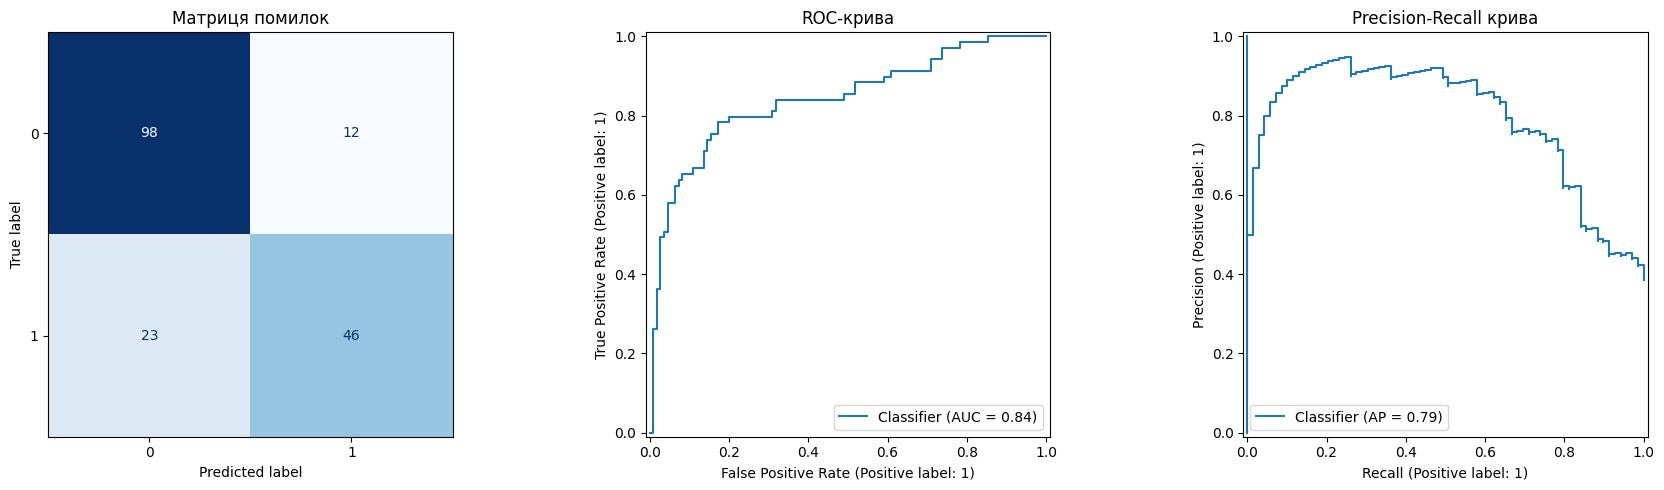

In [9]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def classification_metrics(y_true, y_hat):
  return {
      "accuracy": accuracy_score(y_true, y_hat),
      "precision": precision_score(y_true, y_hat, zero_division=0),
      "recall": recall_score(y_true, y_hat, zero_division=0),
      "f1": f1_score(y_true, y_hat, zero_division=0),
  }


# Порівняльна таблиця метрик
results = pd.DataFrame(
    [
        classification_metrics(y_test, baseline_pred),
        classification_metrics(y_test, y_pred),
    ],
    index=["DummyClassifier", "LogisticRegression"],
)

results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = (
    average_precision_score(y_test, y_proba)
)

display(results.round(3))

# Візуалізації: Матриця помилок, ROC та PR криві
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Матриця помилок")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("ROC-крива")

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title("Precision-Recall крива")

plt.tight_layout()
plt.show()

Висновок до Етапу 8: Порівняння з базовою моделлю: Логістична регресія суттєво перевершила базову модель (DummyClassifier) за всіма ключовими метриками (Accuracy, Precision, Recall, F1-score), що доводить ефективність використання ознак та побудованої моделі.

Матриця помилок (Confusion Matrix): Дозволила чітко побачити співвідношення правильних і хибних відповідей. Модель успішно розпізнає більшість пасажирів, проте містить певну кількість як хибнопозитивних (FP), так і хибнонегативних (FN) помилок.

ROC-крива та ROC AUC: Отримана крива суттєво відхиляється від діагоналі у верхній лівий кут, а високе значення ROC AUC свідчить про те, що модель чудово ранжує пасажирів за ймовірністю виживання незалежно від обраного порога.

Precision–Recall-крива та Average Precision: Крива та показник Average Precision підтверджують прийнятний баланс між точністю і повнотою прогнозів для позитивного класу (виживання), хоча для рідкісних класів точність вимагає додаткової уваги до налаштування порога.

In [10]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
  pred_t = (y_proba >= threshold).astype(int)
  row = classification_metrics(y_test, pred_t)
  row["threshold"] = threshold
  threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_results.round(3))

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


Висновок до Етапу 9: Досліджено вплив порога класифікації на метрики. Зміна порога демонструє класичний компроміс між точністю (precision) та повнотою (recall): зменшення порога збільшує повноту, а збільшення — точність.

In [11]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

false_positive = error_analysis.query("actual == 0 and predicted == 1")
false_negative = error_analysis.query("actual == 1 and predicted == 0")

print("--- Хибнопозитивні помилки (FP) ---")
display(false_positive.sort_values("probability", ascending=False).head())

print("--- Хибнонегативні помилки (FN) ---")
display(false_negative.sort_values("probability").head())

--- Хибнопозитивні помилки (FP) ---


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636


--- Хибнонегативні помилки (FN) ---


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


Висновок до Етапу 10: Проведено аналіз найголовніших помилок моделі (FP та FN). Виявлено випадки, де модель занадто впевнено помилилася, що обумовлено обмеженістю доступних ознак (наприклад, відсутністю даних про індивідуальні обставиди евакуації).



In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Налаштування крос-валідації на 5 фолдів з фіксацією SEED
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Оцінка стабільності кількох метрик на навчальній вибірці
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
)

# Зведення результатів у зручну таблицю
cv_summary = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "ROC AUC",
        ],
        "Mean Score": [
            cv_results["test_accuracy"].mean(),
            cv_results["test_precision"].mean(),
            cv_results["test_recall"].mean(),
            cv_results["test_f1"].mean(),
            cv_results["test_roc_auc"].mean(),
        ],
        "Std Deviation": [
            cv_results["test_accuracy"].std(),
            cv_results["test_precision"].std(),
            cv_results["test_recall"].std(),
            cv_results["test_f1"].std(),
            cv_results["test_roc_auc"].std(),
        ],
    }
).set_index("Metric")

display(cv_summary.round(3))

,Mean Score,Std Deviation
Metric,,
Accuracy,0.802,0.014
Precision,0.765,0.027
Recall,0.700,0.037
F1-score,0.730,0.022
ROC AUC,0.853,0.022


Висновок до індивідуального завдання (Варіант 9): Виконано оцінку стабільності моделі за допомогою StratifiedKFold з 5 фолдами. Невеликі значення стандартного відхилення (Std Deviation) для основних метрик свідчать про високу стійкість та надійність побудованої моделі на різних підмножинах даних.